# MNIST Digit Classification
In this notebook, we will load, preprocess, build, train, and evaluate two different neural network architectures (Fully Connected and CNN) on the classic MNIST dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Load the MNIST dataset
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

print(f"X_train shape: {X_train_raw.shape}")
print(f"y_train shape: {y_train_raw.shape}")
print(f"X_test shape: {X_test_raw.shape}")
print(f"y_test shape: {y_test_raw.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


## Model 1: Fully Connected Neural Network
We will preprocess the data by flattening and normalizing the inputs, and one-hot encoding the labels.

In [2]:
# 2. Preprocess for Fully Connected Network
# Flatten the images to 784 pixels
X_train_flat = X_train_raw.reshape(-1, 28 * 28).astype("float32")
X_test_flat = X_test_raw.reshape(-1, 28 * 28).astype("float32")

# Normalize pixel values
X_train_flat /= 255.0
X_test_flat /= 255.0

# One-hot encode the target labels
y_train_cat = keras.utils.to_categorical(y_train_raw, 10)
y_test_cat = keras.utils.to_categorical(y_test_raw, 10)

print("Fully Connected preprocessed shapes:")
print(f"X_train_flat: {X_train_flat.shape}")
print(f"y_train_cat: {y_train_cat.shape}")

Fully Connected preprocessed shapes:
X_train_flat: (60000, 784)
y_train_cat: (60000, 10)


In [3]:
# 3. Build and Train Fully Connected Network
fc_model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(512, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

fc_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fc_model.summary()

# Train the model
fc_history = fc_model.fit(
    X_train_flat, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate
fc_loss, fc_acc = fc_model.evaluate(X_test_flat, y_test_cat, verbose=0)
print(f"\nFully Connected Test Accuracy: {fc_acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,874 (1.79 MB)

 Trainable params: 468,874 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9262 - loss: 0.2540 - val_accuracy: 0.9685 - val_loss: 0.1058
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9721 - loss: 0.0931 - val_accuracy: 0.9737 - val_loss: 0.0871
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9816 - loss: 0.0601 - val_accuracy: 0.9755 - val_loss: 0.0826
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9880 - loss: 0.0393 - val_accuracy: 0.9803 - val_loss: 0.0674
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9912 - loss: 0.0284 - val_accuracy: 0.9810 - val_loss: 0.0693
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9921 - loss: 0.0237 - val_accuracy: 0.9773 - val_loss: 0.0866
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9815 - val_loss: 0.0698
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9953 - loss: 0.0149 - val_acc

## Model 2: Convolutional Neural Network (CNN)
For CNN, we retain the 2D spatial dimensions and add a single channel dimension.

In [4]:
# 4. Preprocess for CNN
# Reshape to include the single channel dimension (grayscale)
X_train_cnn = X_train_raw.reshape(-1, 28, 28, 1).astype("float32")
X_test_cnn = X_test_raw.reshape(-1, 28, 28, 1).astype("float32")

# Normalize pixel values
X_train_cnn /= 255.0
X_test_cnn /= 255.0

print("CNN preprocessed shapes:")
print(f"X_train_cnn: {X_train_cnn.shape}")

CNN preprocessed shapes:
X_train_cnn: (60000, 28, 28, 1)


In [5]:
# 5. Build and Train CNN
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

# Train the model
cnn_history = cnn_model.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nCNN Test Accuracy: {cnn_acc:.4f}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 103ms/step - accuracy: 0.9343 - loss: 0.2218 - val_accuracy: 0.9800 - val_loss: 0.0654
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 104ms/step - accuracy: 0.9817 - loss: 0.0593 - val_accuracy: 0.9865 - val_loss: 0.0429
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 102ms/step - accuracy: 0.9875 - loss: 0.0409 - val_accuracy: 0.9895 - val_loss: 0.0409
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 102ms/step - accuracy: 0.9903 - loss: 0.0311 - val_accuracy: 0.9923 - val_loss: 0.0331
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9926 - loss: 0.0239 - val_accuracy: 0.9903 - val_loss: 0.0370
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9941 - loss: 0.0185 - val_accuracy: 0.9900 - val_loss: 0.0334
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9946 - loss: 0.0166 - val_accuracy: 0.9880 - val_loss: 0.0460
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9959 - loss: 0

## Model Comparison
Let's plot and compare the training histories and test performance of both models.

Fully Connected Network Accuracy: 97.56%
Convolutional Neural Network Accuracy: 98.99%


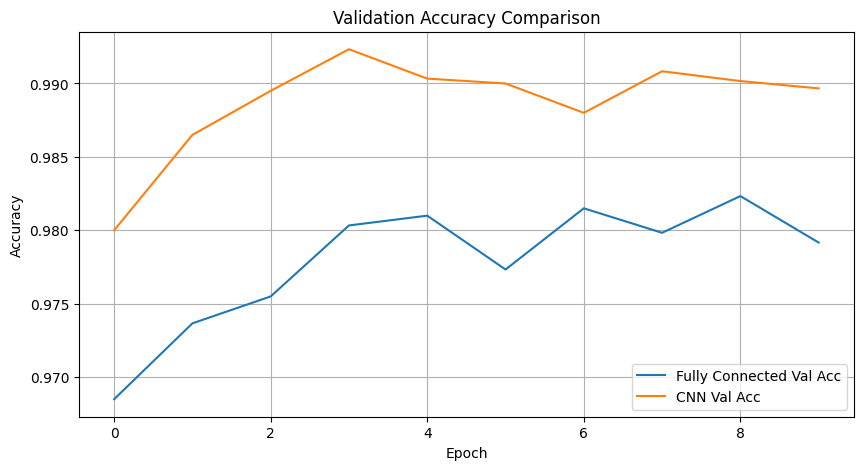

In [6]:
# 6. Compare Performance
print(f"Fully Connected Network Accuracy: {fc_acc * 100:.2f}%")
print(f"Convolutional Neural Network Accuracy: {cnn_acc * 100:.2f}%")

# Plot validation accuracy comparison
plt.figure(figsize=(10, 5))
plt.plot(fc_history.history['val_accuracy'], label='Fully Connected Val Acc')
plt.plot(cnn_history.history['val_accuracy'], label='CNN Val Acc')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()